# Day 75: Google Trends data

Combine Google Trends search data with Tesla, Bitcoin and unemployment time
series. This notebook walks the lecture with the `google_trends_data` package:
explore, clean and prepare the data, then draw the charts.

Every run starts by loading the CSV files again, so the notebook can be run from
the top as often as you like.

## Import the packages and load the data

`load_data` creates the gateway to the five course CSV files in `data/`.

In [1]:
%matplotlib inline

from google_trends_data.domain.datasets import DatasetName
from google_trends_data.presentation.bootstrap import create_renderer, load_data
from google_trends_data.presentation.lecture import (
    convert_dates,
    count_missing,
    describe_data,
    draw_chart,
    drop_missing,
    format_summary,
    resample_monthly,
)

gateway = load_data()
renderer = create_renderer()

## Data Exploration

Shape, column names, minimum, maximum and periodicity of each dataset. Tesla,
unemployment and Bitcoin search are monthly; the Bitcoin price is daily.

### Tesla: web search trend vs stock price

In [2]:
print(format_summary(describe_data(gateway, DatasetName.TESLA)))

tesla: 124 rows x 3 columns
columns: MONTH, TSLA_WEB_SEARCH, TSLA_USD_CLOSE
periodicity: monthly
TSLA_WEB_SEARCH: min 2, max 31
TSLA_USD_CLOSE: min 3.896, max 498.32


### Unemployment: benefits web search vs unemployment rate

In [3]:
print(format_summary(describe_data(gateway, DatasetName.UNEMPLOYMENT)))

unemployment: 181 rows x 3 columns
columns: MONTH, UE_BENEFITS_WEB_SEARCH, UNRATE
periodicity: monthly
UE_BENEFITS_WEB_SEARCH: min 14, max 100
UNRATE: min 3.7, max 10


### Bitcoin: news search trend and daily price

In [4]:
print(format_summary(describe_data(gateway, DatasetName.BTC_SEARCH)))
print()
print(format_summary(describe_data(gateway, DatasetName.BTC_PRICE)))

btc_search: 73 rows x 2 columns
columns: MONTH, BTC_NEWS_SEARCH
periodicity: monthly
BTC_NEWS_SEARCH: min 3, max 100

btc_price: 2204 rows x 3 columns
columns: DATE, CLOSE, VOLUME
periodicity: daily
CLOSE: min 178.103, max 19497.4
VOLUME: min 5.91457e+06, max 7.41568e+10


## Check for Missing Values

`count_missing` counts the missing values and names the rows that hold them.

In [5]:
for name in (
    DatasetName.TESLA,
    DatasetName.UNEMPLOYMENT,
    DatasetName.BTC_SEARCH,
    DatasetName.BTC_PRICE,
):
    print(count_missing(gateway, name))

MissingReport(name=<DatasetName.TESLA: 'tesla'>, missing_values=0, rows_with_missing=())
MissingReport(name=<DatasetName.UNEMPLOYMENT: 'unemployment'>, missing_values=0, rows_with_missing=())
MissingReport(name=<DatasetName.BTC_SEARCH: 'btc_search'>, missing_values=0, rows_with_missing=())
MissingReport(name=<DatasetName.BTC_PRICE: 'btc_price'>, missing_values=2, rows_with_missing=(2148,))


## Remove Missing Values

The Bitcoin price has two missing values, both in row 2148, so we drop that row.

In [6]:
print(drop_missing(gateway, DatasetName.BTC_PRICE))

CleaningResult(name=<DatasetName.BTC_PRICE: 'btc_price'>, removed_rows=1, remaining_rows=2203)


## Convert Strings to DateTime Objects

The date columns are read as strings. Convert all five datasets to datetime.

In [7]:
for name in DatasetName:
    print(convert_dates(gateway, name))

DateConversionResult(name=<DatasetName.TESLA: 'tesla'>, column='MONTH', is_datetime=True)
DateConversionResult(name=<DatasetName.UNEMPLOYMENT: 'unemployment'>, column='MONTH', is_datetime=True)
DateConversionResult(name=<DatasetName.BTC_SEARCH: 'btc_search'>, column='MONTH', is_datetime=True)
DateConversionResult(name=<DatasetName.BTC_PRICE: 'btc_price'>, column='DATE', is_datetime=True)
DateConversionResult(name=<DatasetName.UNEMPLOYMENT_2020: 'unemployment_2020'>, column='MONTH', is_datetime=True)


## Converting from Daily to Monthly Data

The Bitcoin price is daily; resample it to the last value of each month so it
lines up with the monthly search trend: 73 months from 2014-09-30 to 2020-09-30.

In [8]:
print(resample_monthly(gateway))

ResampleResult(name=<DatasetName.BTC_PRICE: 'btc_price'>, rows=73, first_month=datetime.date(2014, 9, 30), last_month=datetime.date(2020, 9, 30))


## Charts

Each chart step builds on the previous one. `draw_chart` takes the gateway, the
renderer and the step key.

### Tesla: price and search trend on two axes

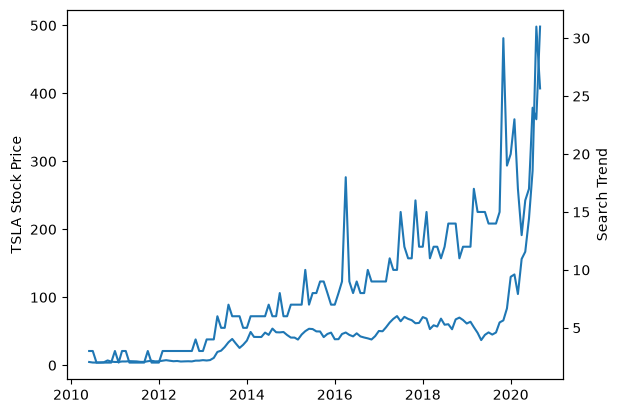

In [9]:
draw_chart(gateway, renderer, "tesla-1-basic")

### Tesla: colours for the axis labels

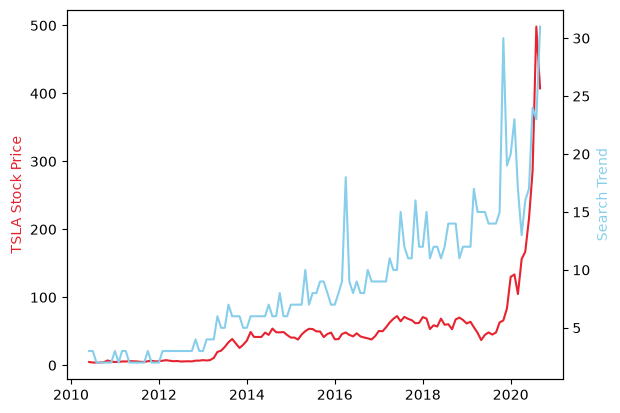

In [10]:
draw_chart(gateway, renderer, "tesla-2-colours")

### Tesla: larger figure, fonts, rotated ticks and thicker lines

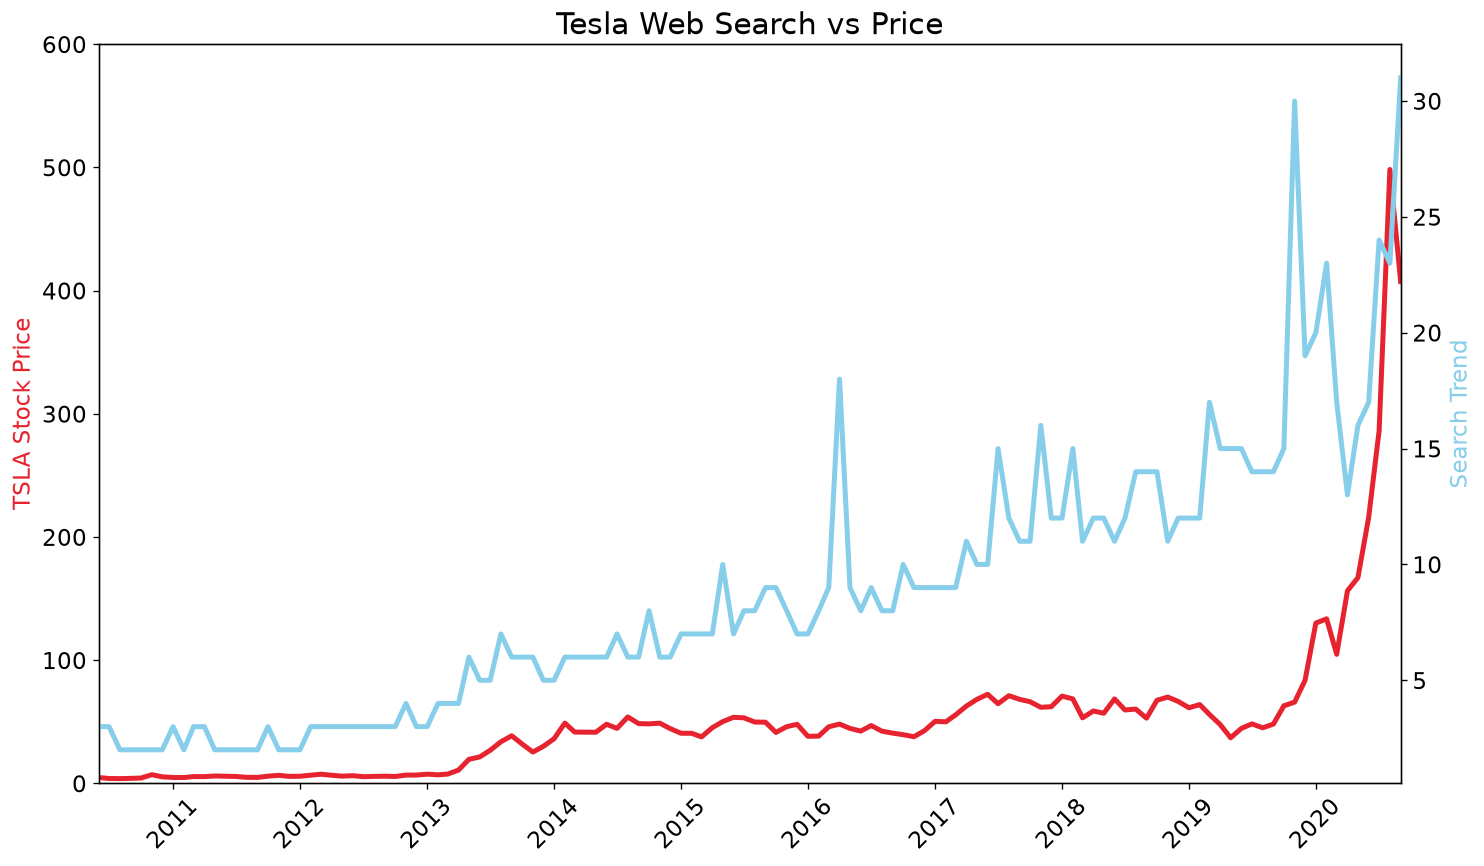

In [11]:
draw_chart(gateway, renderer, "tesla-3-styled")

### Tesla: year and month locators on the x axis

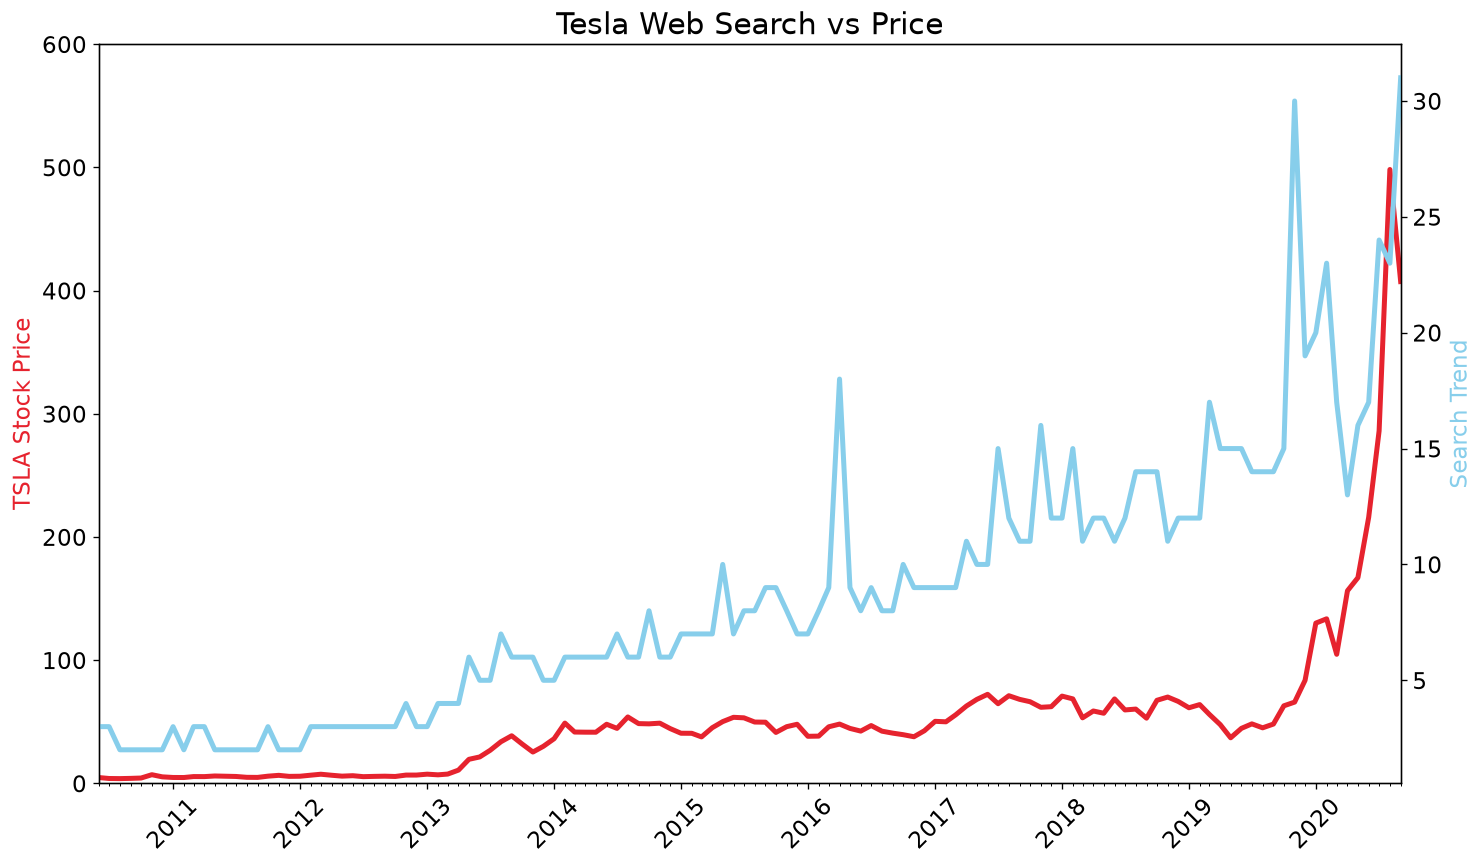

In [12]:
draw_chart(gateway, renderer, "tesla-4-locators")

### Bitcoin: monthly price (dashed) and news search (circles)

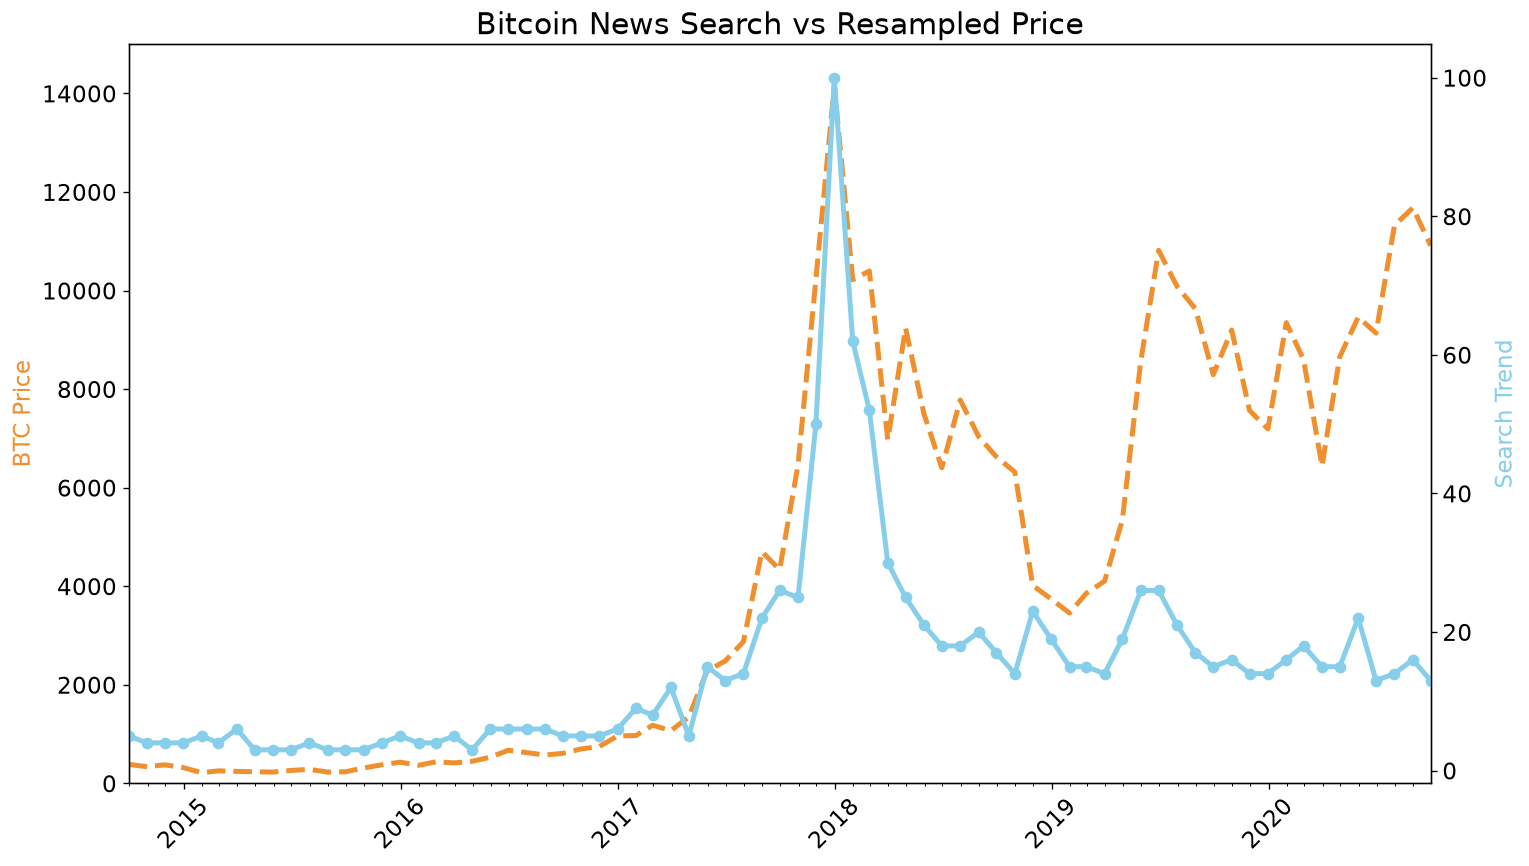

In [13]:
draw_chart(gateway, renderer, "bitcoin")

### Unemployment: grid, axis limits and a title

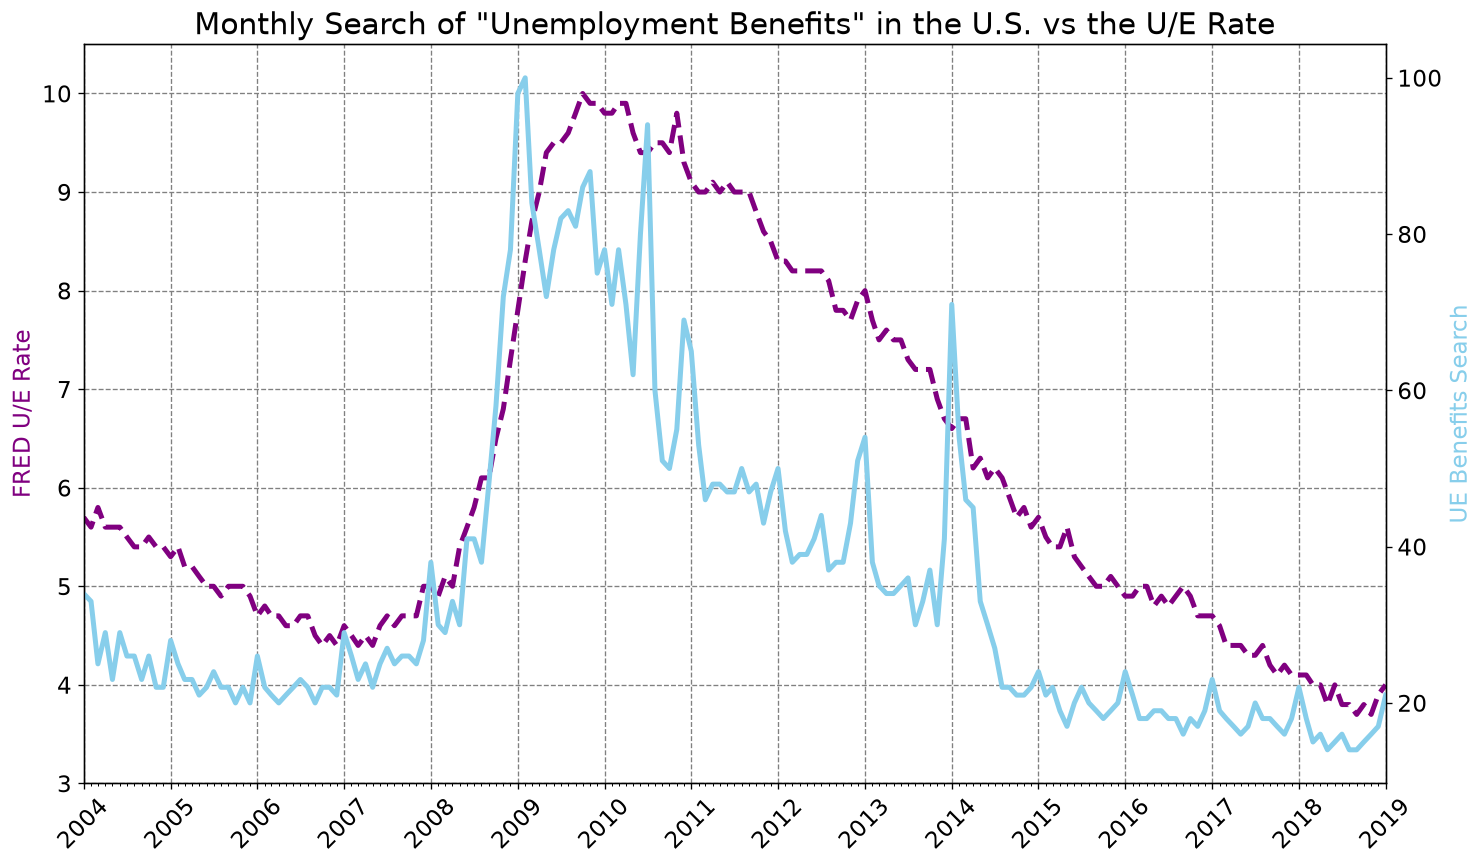

In [14]:
draw_chart(gateway, renderer, "unemployment-grid")

### Unemployment: six month rolling average of the search trend

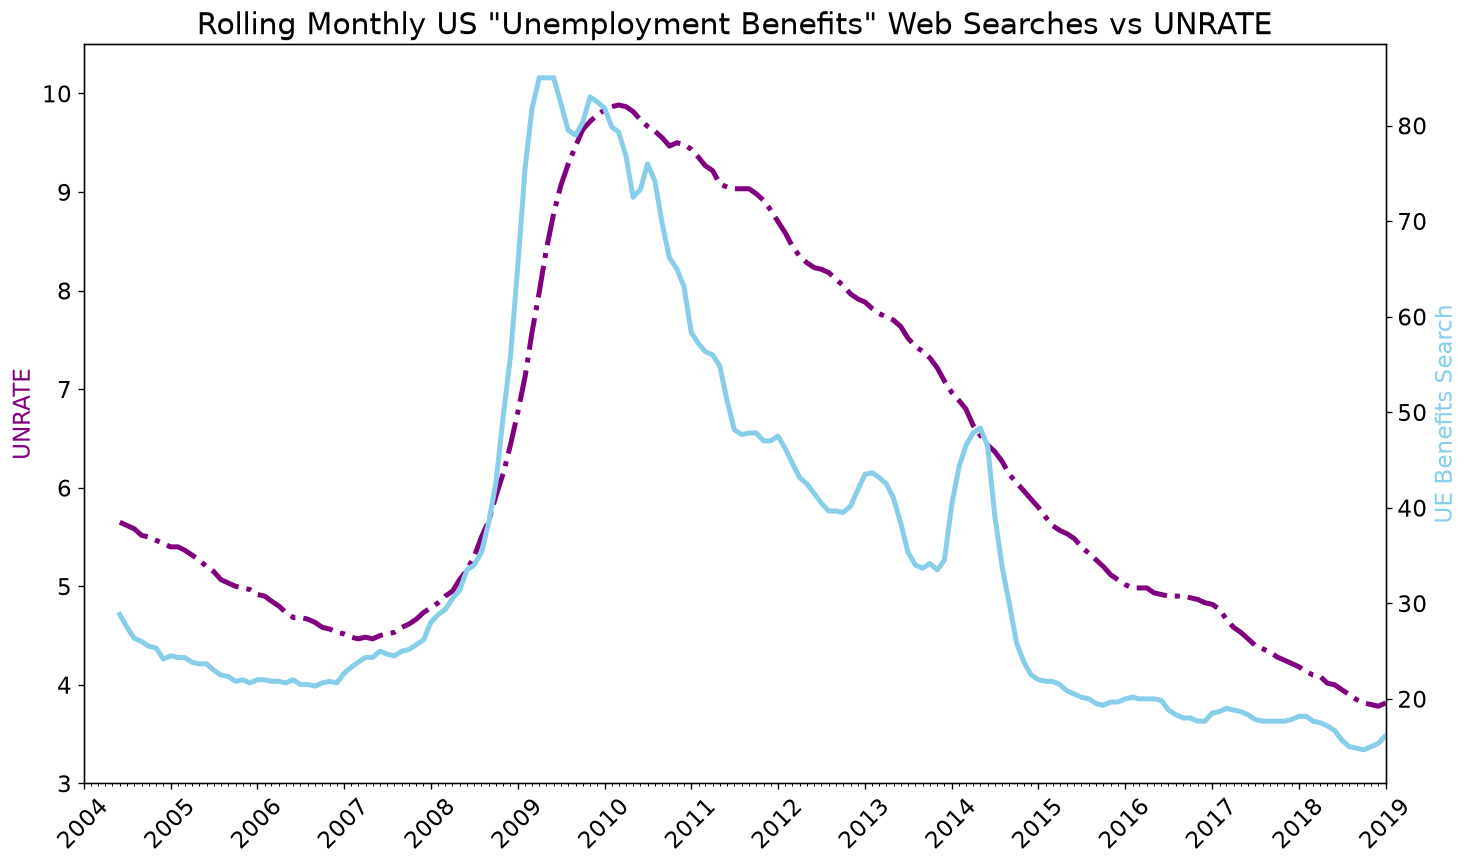

In [15]:
draw_chart(gateway, renderer, "unemployment-rolling")

### Unemployment: the data including 2020

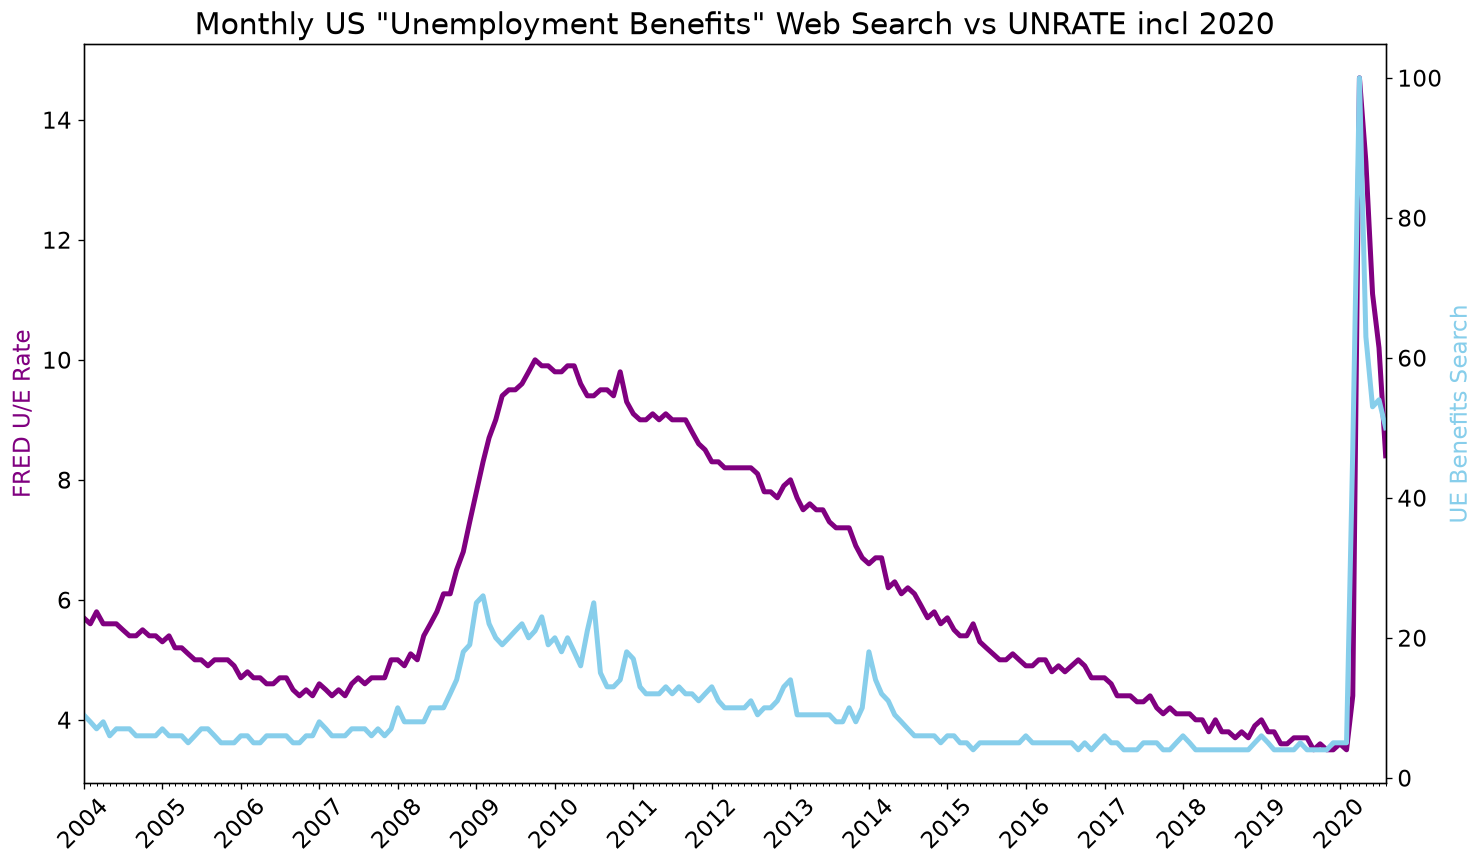

In [16]:
draw_chart(gateway, renderer, "unemployment-2020")